<a href="https://colab.research.google.com/github/gangambikeganga/Women-Safety-Alert-App/blob/main/round%201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd ,numpy as np
np.random.seed(42)

rows = []
for m in ["Motor-1", "Motor-2", "Motor-3"]:
    for minute in range(30):
        rows.append([m, minute,
                     round(np.random.normal(70, 3), 1),
                     round(np.random.normal(2.0, 0.3), 2)])

df = pd.DataFrame(rows, columns=["machine", "minute", "temp", "vibration"])

# Motor-3 ge fault inject (last 5 minutes)
mask = (df.machine == "Motor-3") & (df.minute >= 25)
df.loc[mask, "temp"] = [88, 91, 93, 95, 96]
df.loc[mask, "vibration"] = [3.8, 4.1, 4.4, 4.6, 4.9]

df.to_csv("sensor_data.csv", index=False)
print("sensor_data.csv created with", len(df), "rows")
df.tail(8)

sensor_data.csv created with 90 rows


,machine,minute,temp,vibration
82,Motor-3,22,72.9,2.12
83,Motor-3,23,72.5,2.57
84,Motor-3,24,69.3,1.77
85,Motor-3,25,88.0,3.80
86,Motor-3,26,91.0,4.10
87,Motor-3,27,93.0,4.40
88,Motor-3,28,95.0,4.60
89,Motor-3,29,96.0,4.90


In [2]:
TEMP_LIMIT, VIB_LIMIT = 80, 3.5

df = pd.read_csv("sensor_data.csv")
df["abnormal"] = (df.temp > TEMP_LIMIT) | (df.vibration > VIB_LIMIT)
alerts = df[df.abnormal]
print("Readings scanned:", len(df), "| Abnormal readings:", len(alerts))

for machine in alerts.machine.unique():
    last = alerts[alerts.machine == machine].iloc[-1]
    high = last.temp > 90 and last.vibration > 4
    print("=" * 40)
    print("INCIDENT REPORT")
    print("Machine   :", machine)
    print("Time      : minute", last.minute)
    print("Temp      :", last.temp, "C (limit", TEMP_LIMIT, ")")
    print("Vibration :", last.vibration, "(limit", VIB_LIMIT, ")")
    print("Severity  :", "HIGH" if high else "MEDIUM")
    print("Action    :", "Escalate to human review" if high
          else "Recommend inspection")

Readings scanned: 90 | Abnormal readings: 5
INCIDENT REPORT
Machine   : Motor-3
Time      : minute 29
Temp      : 96.0 C (limit 80 )
Vibration : 4.9 (limit 3.5 )
Severity  : HIGH
Action    : Escalate to human review


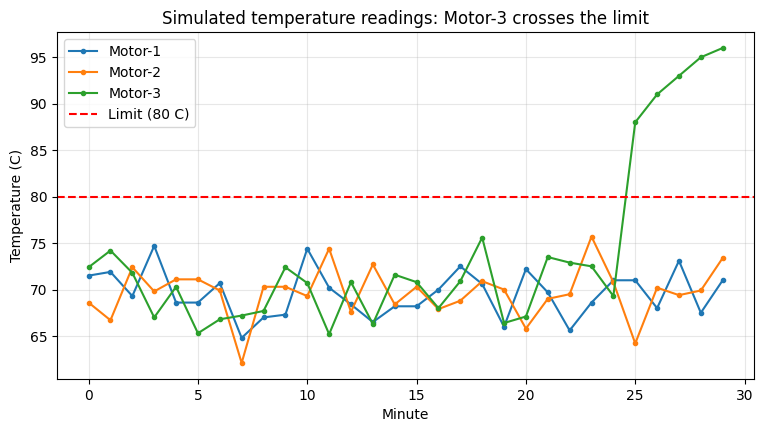

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4.5))
for m in df.machine.unique():
    d = df[df.machine == m]
    plt.plot(d.minute, d.temp, marker="o", markersize=3, label=m)
plt.axhline(TEMP_LIMIT, color="red", linestyle="--", label="Limit (80 C)")
plt.title("Simulated temperature readings: Motor-3 crosses the limit")
plt.xlabel("Minute")
plt.ylabel("Temperature (C)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("temperature_chart.png", dpi=150, bbox_inches="tight")
plt.show()